In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('StudentsPerformance.csv')
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Pandas
    1. Построить столбчатую диаграмму для столбца parental level of education.
    2. Построить круговую диаграмму для столбца race/ethnicity.
    3. Построить гистограммы (на одном рисунке – один вызов функции) для всех числовых столбцов.

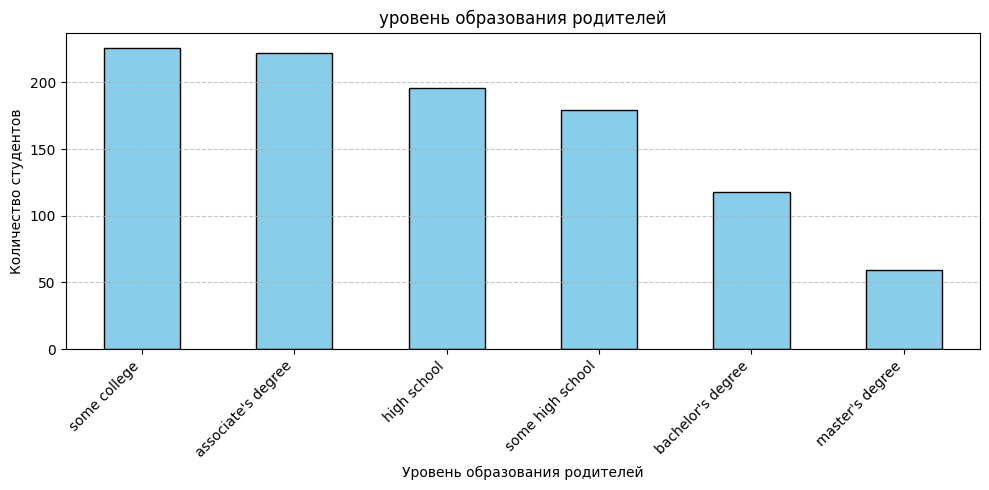

In [3]:
plt.figure(figsize=(10, 5))
df['parental level of education'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('уровень образования родителей')
plt.xlabel('Уровень образования родителей')
plt.ylabel('Количество студентов')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

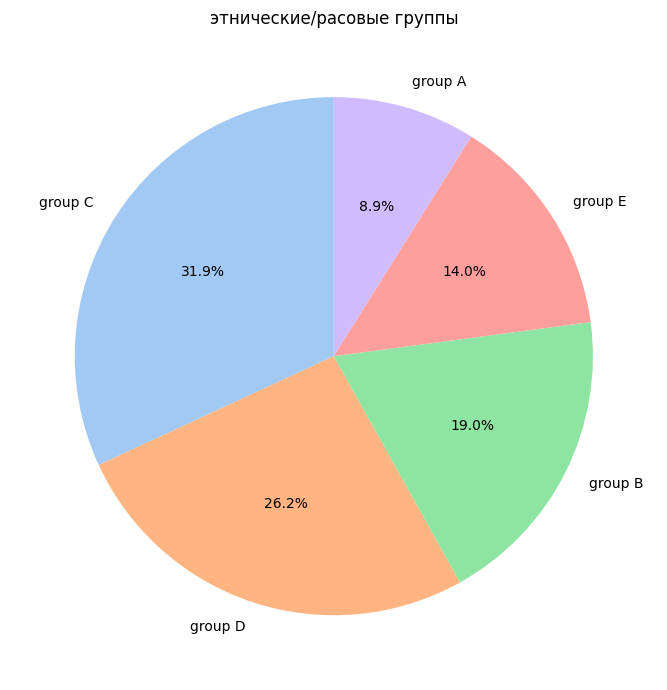

In [4]:
plt.figure(figsize=(7, 7))
df['race/ethnicity'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90,
                                          colors=sns.color_palette('pastel'))
plt.title('этнические/расовые группы')
plt.ylabel('')
plt.tight_layout()
plt.show()

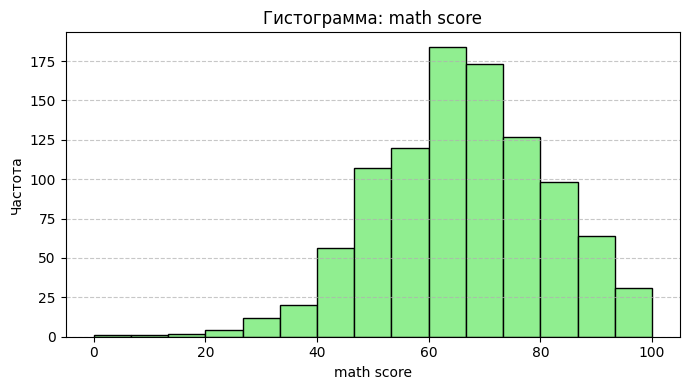

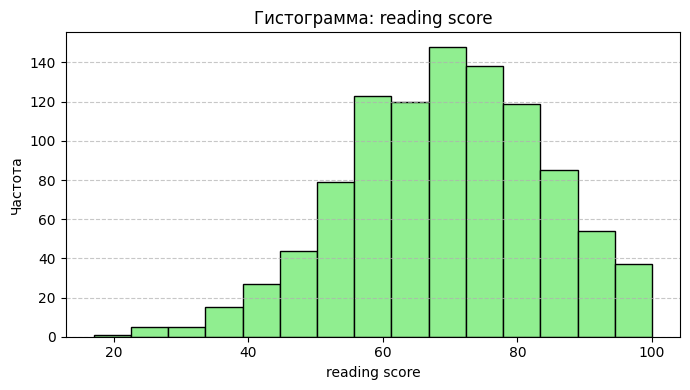

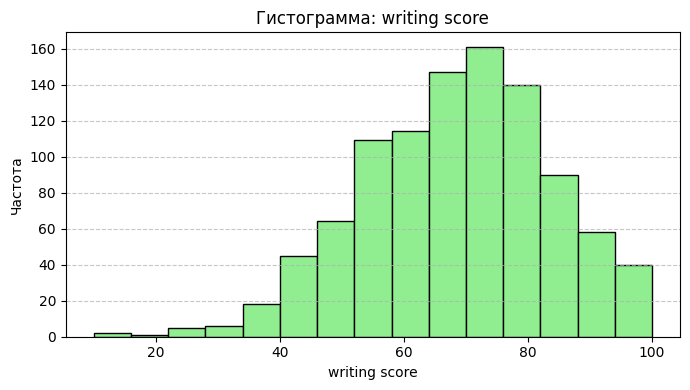

In [6]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    plt.figure(figsize=(7, 4))
    df[col].plot(kind='hist', bins=15, color='lightgreen', edgecolor='black')
    plt.title(f'Гистограмма: {col}')
    plt.xlabel(col)
    plt.ylabel('Частота')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

Matplotlib
Изобразить набор графиков (используем subplots(32X)
X=1	X=2
X=3	X=4
X=5	X=6

    1. X=1. На одном рисунке графики функций (x меняется от -2π до 2π): y1=Cos(2x) и y2=2Cos(x). Первый график  жёлтый, второй  красный. Добавляем сетку.
    2. X=2. “Ящик с усами” для столбца math score. Есть ли выбросы (экстремальные значения оценок)?
    3. X=3. Комбинированный график. Для столбца race/ethnicity  столбчатая диаграмма+график.
    4. X=4. Текст HELLO!!!
    5. X=5. Диаграмма рассеяния 3D(точечный график 3D) для столбцов math score +reading score + writing score.
    6. X=6. Круговая диаграмма (с %) для столбца parental level of education (только для юношей  gender=mail).

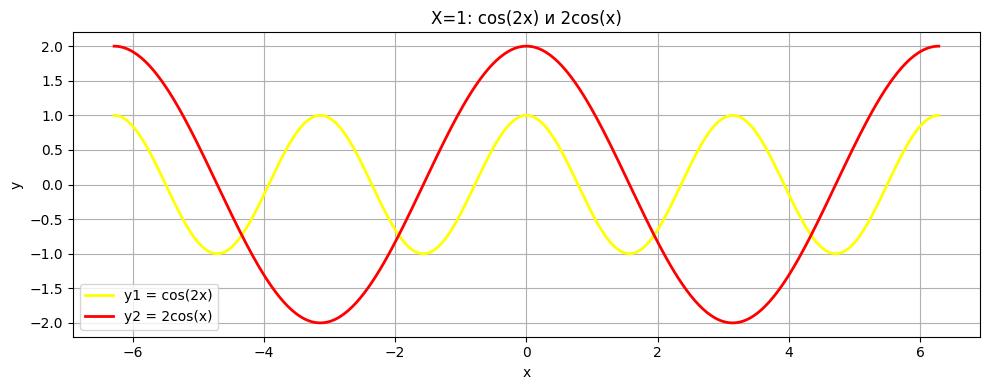

In [7]:
x = np.linspace(-2*np.pi, 2*np.pi, 400)
y1 = np.cos(2*x)
y2 = 2*np.cos(x)

plt.figure(figsize=(10, 4))
plt.plot(x, y1, color='yellow', linewidth=2, label='y1 = cos(2x)')
plt.plot(x, y2, color='red', linewidth=2, label='y2 = 2cos(x)')
plt.title('X=1: cos(2x) и 2cos(x)')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

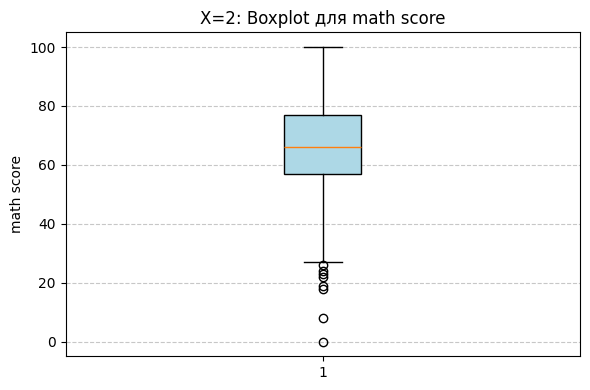

In [8]:
plt.figure(figsize=(6, 4))
plt.boxplot(df['math score'], patch_artist=True,
            boxprops=dict(facecolor='lightblue'))
plt.title('X=2: Boxplot для math score')
plt.ylabel('math score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



есть выброс 0

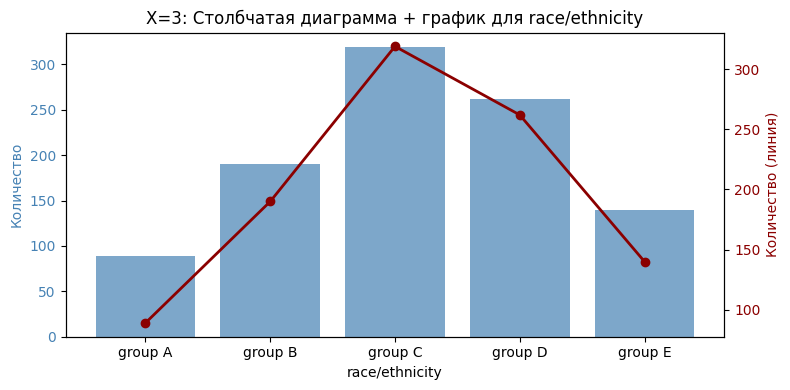

In [9]:
counts = df['race/ethnicity'].value_counts().sort_index()

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(counts.index, counts.values, color='steelblue', alpha=0.7, label='Столбцы (count)')
ax1.set_xlabel('race/ethnicity')
ax1.set_ylabel('Количество', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.plot(counts.index, counts.values, color='darkred', marker='o', linewidth=2, label='Линия (count)')
ax2.set_ylabel('Количество (линия)', color='darkred')
ax2.tick_params(axis='y', labelcolor='darkred')

plt.title('X=3: Столбчатая диаграмма + график для race/ethnicity')
fig.tight_layout()
plt.show()

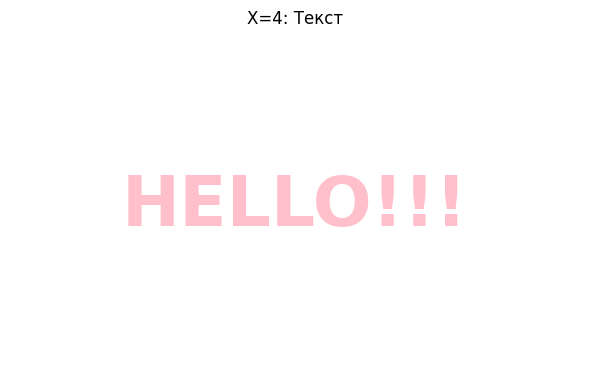

In [11]:
plt.figure(figsize=(6, 4))
plt.text(0.5, 0.5, 'HELLO!!!', fontsize=50, fontweight='bold',
         color='pink', ha='center', va='center')
plt.axis('off')
plt.title('X=4: Текст')
plt.tight_layout()
plt.show()

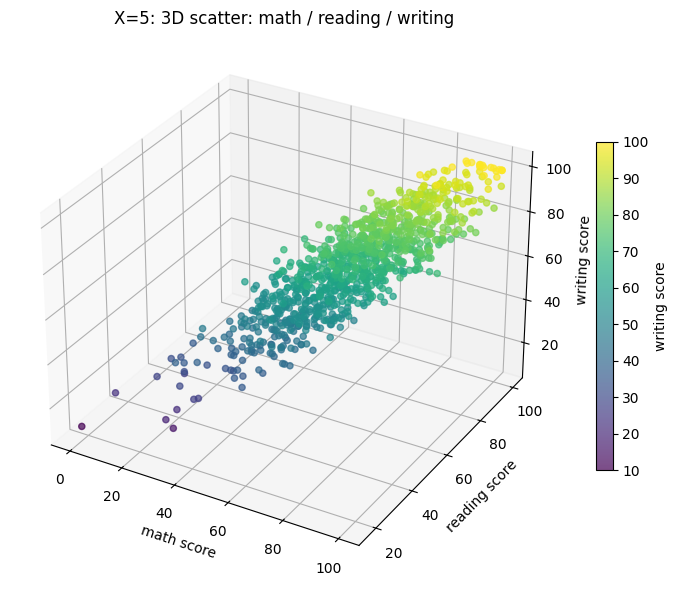

In [12]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(df['math score'], df['reading score'], df['writing score'],
                c=df['writing score'], cmap='viridis', s=20, alpha=0.7)
ax.set_xlabel('math score')
ax.set_ylabel('reading score')
ax.set_zlabel('writing score')
ax.set_title('X=5: 3D scatter: math / reading / writing')
fig.colorbar(sc, ax=ax, shrink=0.6, label='writing score')
plt.tight_layout()
plt.show()

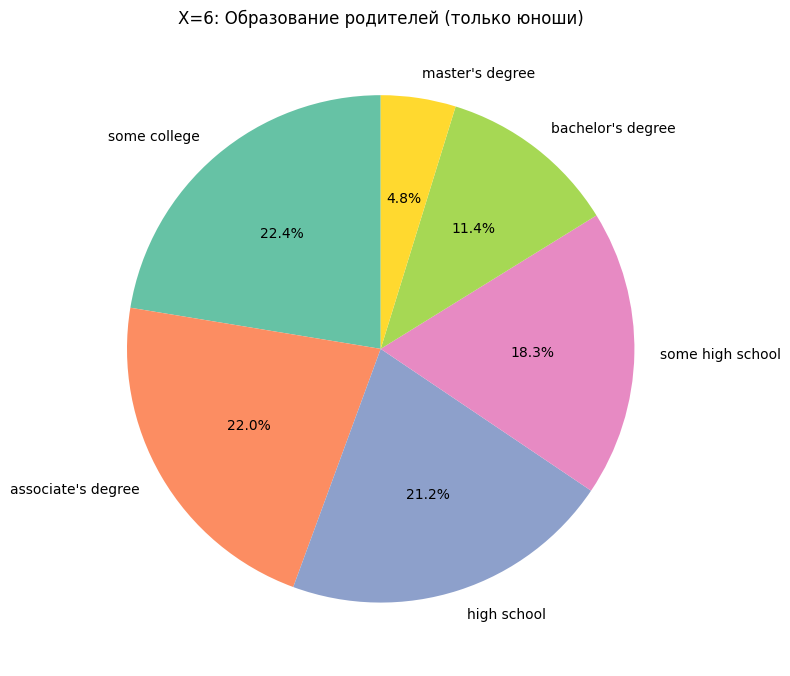

In [13]:
male_df = df[df['gender'] == 'male']
counts = male_df['parental level of education'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%',
        startangle=90, colors=sns.color_palette('Set2'))
plt.title('X=6: Образование родителей (только юноши)')
plt.tight_layout()
plt.show()

Seaborn
    1. Гистограммы по диагонали + диаграммы рассеяния для числовых столбцов (функция pairplot – числовые значения отбираются из df автоматически).
    2. kde по диагонали + диаграммы рассеяния для числовых столбцов (функция pairplot – числовые значения отбираются из df автоматически) с “кластеризацией” (hue=) по полу (gender).
    3. Тепловая карта для числовых столбцов.

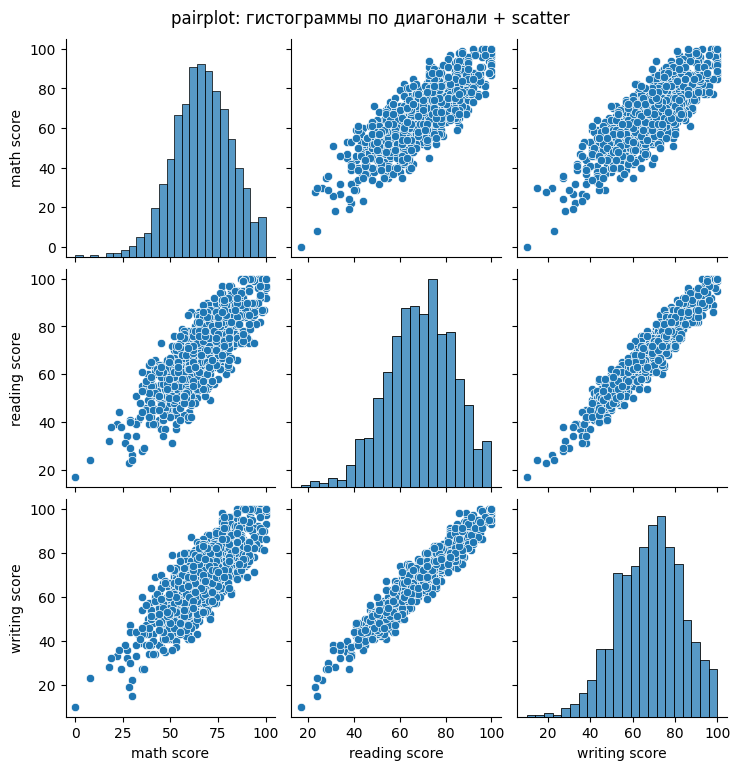

In [14]:
sns.pairplot(df, diag_kind='hist', corner=False)
plt.suptitle('pairplot: гистограммы по диагонали + scatter', y=1.02)
plt.show()

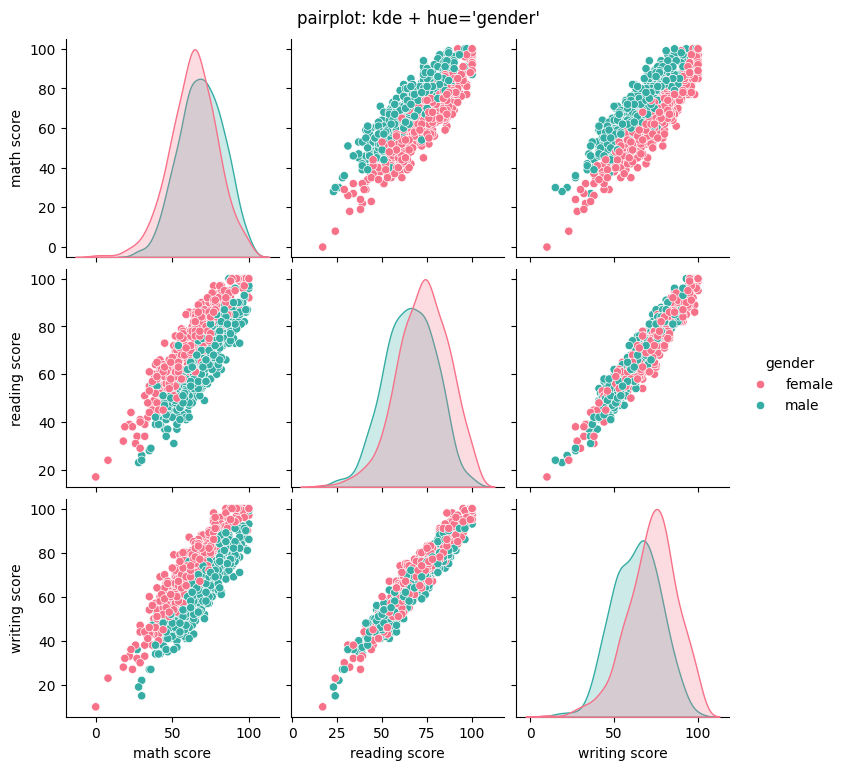

In [15]:
sns.pairplot(df, diag_kind='kde', hue='gender', palette='husl')
plt.suptitle("pairplot: kde + hue='gender'", y=1.02)
plt.show()

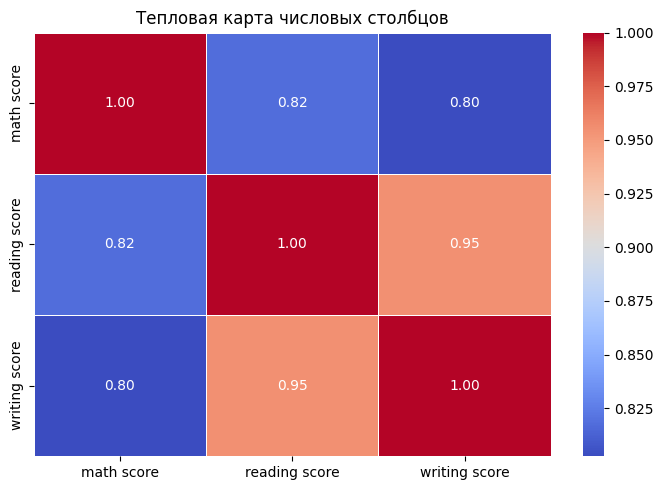

In [17]:
plt.figure(figsize=(7, 5))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Тепловая карта числовых столбцов')
plt.tight_layout()
plt.show()